# One-Sugar Bayesian Microbial Growth Analysis — Revised Modified-Hazard Version

This notebook keeps the same overall idea as the original `one_sugar_modified_hazard_analysis.ipynb`: analyze **one sugar at a time** using a modified survival/hazard model, fit the model by MLE + `emcee`, summarize the posterior, and compare real data with posterior-predictive simulations.

The revision improves the parts that were similar to the previous Model 2 notebooks:

- robust real-data loading and cleaning,
- lineage-aware preprocessing and initial-mass extraction,
- numerically stable survival, hazard, and log-likelihood functions,
- safer MLE and MCMC initialization,
- posterior summaries with mode/median/credible intervals,
- trace plots and corner plots,
- posterior-predictive simulations,
- real-vs-simulated ACF plots.

The core modified model is still the one from your notebook:

$$
S(p)=\frac{1}{\left(1+(p/u)^v\right)^{\omega_2}},
\qquad
p(t)=m_b\left(e^{\alpha t}-1\right).
$$


## 1. Imports and user settings

Change only the settings in this cell when you want to analyze another sugar or run a longer chain.


In [44]:

from pathlib import Path
import math
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize, root_scalar
from scipy.special import gammaln, betaln
from scipy.stats import gamma as scipy_gamma
from scipy.stats import beta as scipy_beta

import emcee

try:
    import corner
    HAS_CORNER = True
except ImportError:
    HAS_CORNER = False
    print("corner is not installed. The corner plot cell will be skipped.")

# ---------------------------------------------------------------------
# Numerical constants
# ---------------------------------------------------------------------
EPS = 1e-300
LOG_EPS = np.log(EPS)
MAX_EXP_ARG = 700.0

# ---------------------------------------------------------------------
# One-sugar settings
# ---------------------------------------------------------------------
SUGAR = "Gly"


def resolve_project_dir():
    """
    Resolve the microbial-growth project folder.

    This makes the notebook work when it is run from:
    1. the repository root,
    2. projects/microbial-growth/,
    3. projects/microbial-growth/notebooks/.
    """
    cwd = Path.cwd().resolve()

    # Case 1: running from the repository root.
    repo_project = cwd / "projects" / "microbial-growth"
    if repo_project.exists():
        return repo_project

    # Case 2 or 3: running from inside the project.
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "data").exists() and (candidate / "outputs").exists():
            return candidate

    # Fallback: use current directory.
    return cwd


PROJECT_DIR = resolve_project_dir()

# The notebook checks these paths in order. The first path is the GitHub-ready layout.
DATA_PATH_CANDIDATES = [
    PROJECT_DIR / "data" / "processed" / "processed_input_data.csv",
    PROJECT_DIR / "data" / "raw" / "UMIK_allSources.csv",
    PROJECT_DIR / "data" / "raw" / "df_UMIK_allSources.csv",
    Path("processed_input_data.csv"),
    Path("UMIK_allSources.csv"),
    Path("df_UMIK_allSources.csv"),
]

# MCMC settings. For a quick test, keep these values moderate.
# For a final run, increase N_STEPS and BURN_STEPS.
N_WALKERS = 40
BURN_STEPS = 1000
N_STEPS = 3000
THIN = 5
RANDOM_SEED = 42

# Posterior-predictive simulation settings.
SIM_LINEAGES = 40
SIM_GENERATIONS = 80
ACF_MAX_LAG = 30

# Plotting settings.
DIVISION_TIME_BINS = 25
OTHER_BINS = 40

# Save chain and figures.
SAVE_CHAIN = True
SAVE_FIGURES = False

OUTPUT_DIR = PROJECT_DIR / "outputs" / "notebook_runs" / f"modified_hazard_{SUGAR}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PARAMETER_NAMES = [
    "u",
    "v",
    "omega2",
    "mu_alpha",
    "sigma_alpha",
    "mu_f",
    "sigma_f",
]

rng = np.random.default_rng(RANDOM_SEED)
np.set_printoptions(suppress=True, precision=5)

print("Project directory:", PROJECT_DIR)
print("Notebook output directory:", OUTPUT_DIR)


## 2. Load and clean the one-sugar real data

This section follows the style of the previous real-data Model 2 notebooks, but avoids hard-coded absolute paths and fixes the initial-mass extraction issue by using `.iloc[0]`.

The required real-data columns are:

```text
source, lineage_ID, generation, generationtime, growth_rate, division_ratio, length_birth
```


In [45]:

def find_existing_path(candidates):
    """Return the first existing file path from a list of candidates."""
    for path in candidates:
        if Path(path).exists():
            return Path(path)
    raise FileNotFoundError(
        "Could not find the microbial-growth data file. Tried:\n"
        + "\n".join(str(p) for p in candidates)
        + "\n\nUpdate DATA_PATH_CANDIDATES in the settings cell."
    )


def load_real_data_one_sugar(data_path, sugar):
    """
    Load and clean real microbial-growth data for one sugar.

    Returns
    -------
    df_sugar : pandas.DataFrame
        Cleaned one-sugar dataframe sorted by lineage and generation.
    initial_mass : numpy.ndarray
        Initial birth length for each retained lineage.
    unique_lineages : numpy.ndarray
        Lineage labels corresponding to initial_mass.
    """
    df = pd.read_csv(data_path)

    rename_map = {
        "lineage_ID": "lineage",
        "generationtime": "time",
        "growth_rate": "alpha",
        "division_ratio": "f",
    }
    df = df.rename(columns=rename_map)

    required_cols = [
        "source",
        "lineage",
        "generation",
        "time",
        "alpha",
        "f",
        "length_birth",
    ]

    missing = [col for col in required_cols if col not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    df = df[required_cols].copy()

    # Convert numeric columns safely.
    numeric_cols = ["generation", "time", "alpha", "f", "length_birth"]
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=required_cols)

    # Keep only biologically meaningful observations.
    df = df[df["time"] > 0]
    df = df[df["alpha"] > 0]
    df = df[(df["f"] > 0) & (df["f"] < 1)]
    df = df[df["length_birth"] > 0]

    df_sugar = df[df["source"] == sugar].copy()
    if df_sugar.empty:
        available = sorted(df["source"].dropna().unique())
        raise ValueError(
            f"No rows found for SUGAR={sugar!r}. Available sources are: {available}"
        )

    df_sugar = df_sugar.sort_values(["lineage", "generation"]).reset_index(drop=True)

    # Remove lineages without a generation-0 starting mass.
    retained_lineages = []
    initial_masses = []
    dropped_lineages = []

    for lineage, sub in df_sugar.groupby("lineage", sort=False):
        gen0 = sub[sub["generation"] == 0]
        if gen0.empty:
            dropped_lineages.append(lineage)
            continue
        retained_lineages.append(lineage)
        initial_masses.append(float(gen0["length_birth"].iloc[0]))

    if dropped_lineages:
        warnings.warn(
            f"Dropped {len(dropped_lineages)} lineages without generation 0. "
            f"First few: {dropped_lineages[:5]}"
        )
        df_sugar = df_sugar[df_sugar["lineage"].isin(retained_lineages)].copy()
        df_sugar = df_sugar.sort_values(["lineage", "generation"]).reset_index(drop=True)

    initial_mass = np.asarray(initial_masses, dtype=float)
    unique_lineages = np.asarray(retained_lineages)

    if len(df_sugar) == 0:
        raise ValueError("All rows were dropped during preprocessing.")

    return df_sugar, initial_mass, unique_lineages


DATA_PATH = find_existing_path(DATA_PATH_CANDIDATES)
df_sugar, initial_mass, unique_lineages = load_real_data_one_sugar(DATA_PATH, SUGAR)

print("Data path:", DATA_PATH)
print("Sugar selected:", SUGAR)
print("Number of observations:", len(df_sugar))
print("Number of retained lineages:", len(unique_lineages))
print("Initial-mass array shape:", initial_mass.shape)

df_sugar.head()


Data path: Data\UMIK_allSources.csv
Sugar selected: Gly
Number of observations: 1647
Number of retained lineages: 91
Initial-mass array shape: (91,)


,source,lineage,generation,time,alpha,f,length_birth
0,Gly,575.0,0.0,1.666667,0.396022,0.502742,2.112804
1,Gly,575.0,1.0,1.500000,0.339032,0.521157,2.305271
2,Gly,575.0,2.0,1.000000,0.462285,0.507888,2.034240
3,Gly,575.0,3.0,1.833333,0.412794,0.506883,1.758536
4,Gly,575.0,4.0,1.500000,0.427875,0.512990,2.103593


## 3. Convert the dataframe into arrays

The likelihood uses one row per observed cell cycle. The lineage labels are kept for ACF and diagnostics.


In [46]:

def prepare_sugar_data(df_sugar, initial_mass, unique_lineages):
    """Convert the cleaned one-sugar dataframe into NumPy arrays."""
    return {
        "time": df_sugar["time"].to_numpy(float),
        "alpha": df_sugar["alpha"].to_numpy(float),
        "f": df_sugar["f"].to_numpy(float),
        "length_birth": df_sugar["length_birth"].to_numpy(float),
        "lineage": df_sugar["lineage"].to_numpy(),
        "generation": df_sugar["generation"].to_numpy(float),
        "initial_mass": np.asarray(initial_mass, dtype=float),
        "unique_lineages": np.asarray(unique_lineages),
    }


data = prepare_sugar_data(df_sugar, initial_mass, unique_lineages)

print("First 5 division times:", data["time"][:5])
print("First 5 growth rates:", data["alpha"][:5])
print("First 5 division ratios:", data["f"][:5])
print("First 5 birth lengths:", data["length_birth"][:5])


First 5 division times: [1.66667 1.5     1.      1.83333 1.5    ]
First 5 growth rates: [0.39602 0.33903 0.46229 0.41279 0.42787]
First 5 division ratios: [0.50274 0.52116 0.50789 0.50688 0.51299]
First 5 birth lengths: [2.1128  2.30527 2.03424 1.75854 2.10359]


## 4. Quick data check

These histograms are only a sanity check before fitting. They help catch unusual preprocessing issues before running MCMC.


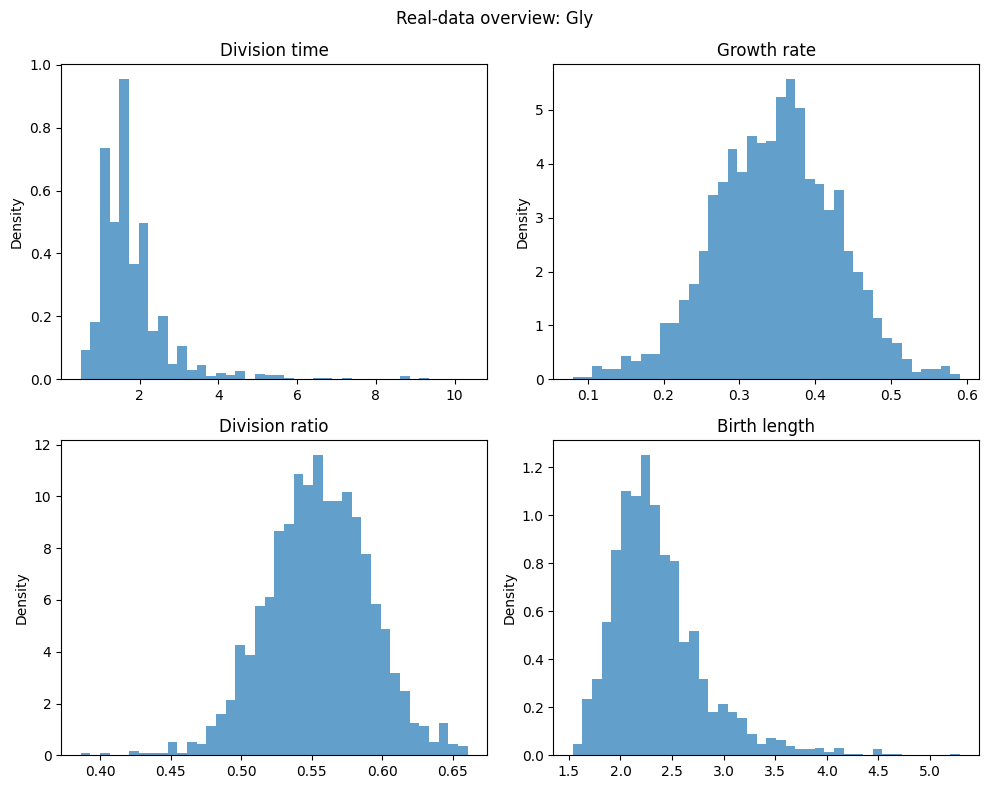

In [47]:

def plot_real_data_overview(df_sugar, sugar):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()

    specs = [
        ("time", "Division time"),
        ("alpha", "Growth rate"),
        ("f", "Division ratio"),
        ("length_birth", "Birth length"),
    ]

    for ax, (col, title) in zip(axes, specs):
        vals = df_sugar[col].to_numpy(float)
        vals = vals[np.isfinite(vals)]
        ax.hist(vals, bins=40, density=True, alpha=0.7)
        ax.set_title(title)
        ax.set_ylabel("Density")

    fig.suptitle(f"Real-data overview: {sugar}")
    fig.tight_layout()

    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"real_data_overview_{sugar}.pdf", bbox_inches="tight")

    plt.show()


plot_real_data_overview(df_sugar, SUGAR)


## 5. Modified survival, hazard, and division-time density

The original notebook computed the hazard/density directly. Here the same model is evaluated mostly in log-space, which is more stable during MLE and MCMC.

The modified survival is:

$$
S(p)=\left(1+(p/u)^v\right)^{-\omega_2}.
$$

The corresponding time hazard is:

$$
h(t)=\frac{\omega_2 v}{u}\frac{(p/u)^{v-1}}{1+(p/u)^v}\frac{dp}{dt},
\qquad
\frac{dp}{dt}=m_b\alpha e^{\alpha t}.
$$


In [48]:

def safe_exp(x):
    """Exponentiate while avoiding overflow."""
    return np.exp(np.clip(x, -MAX_EXP_ARG, MAX_EXP_ARG))


def log_expm1_positive(y):
    """
    Stable approximation to log(expm1(y)) for y >= 0.

    For large y, log(expm1(y)) is approximately y.
    """
    y = np.asarray(y, dtype=float)
    y_clip = np.maximum(y, 0.0)

    small = y_clip < 50.0
    out = np.empty_like(y_clip, dtype=float)
    out[small] = np.log(np.expm1(y_clip[small]) + EPS)
    out[~small] = y_clip[~small]
    return out


def log_protein(t, length_birth, alpha):
    """
    Log of the accumulated division variable:

    p(t) = length_birth * (exp(alpha*t) - 1).
    """
    t = np.asarray(t, dtype=float)
    length_birth = np.asarray(length_birth, dtype=float)
    alpha = np.asarray(alpha, dtype=float)

    return np.log(np.maximum(length_birth, EPS)) + log_expm1_positive(alpha * t)


def protein(t, length_birth, alpha):
    """Accumulated division variable p(t). Useful for diagnostics/initial guesses."""
    return length_birth * np.expm1(np.clip(alpha * t, 0.0, MAX_EXP_ARG))


def log1pexp(z):
    """Stable log(1 + exp(z))."""
    return np.logaddexp(0.0, z)


def log_survival_modified(t, length_birth, alpha, u, v, omega2):
    """Log-survival for the modified hazard model."""
    if not (u > 0 and v > 0 and omega2 > 0):
        return np.full_like(np.asarray(t, dtype=float), -np.inf, dtype=float)

    log_p = log_protein(t, length_birth, alpha)
    log_x = log_p - np.log(u)
    z = v * log_x
    return -omega2 * log1pexp(z)


def survival_modified(t, length_birth, alpha, u, v, omega2):
    """Survival S(t) for the modified hazard model."""
    log_s = log_survival_modified(t, length_birth, alpha, u, v, omega2)
    return np.exp(np.clip(log_s, -745.0, 50.0))


def log_hazard_modified(t, length_birth, alpha, u, v, omega2):
    """Log-hazard for the modified hazard model."""
    if not (u > 0 and v > 0 and omega2 > 0):
        return np.full_like(np.asarray(t, dtype=float), -np.inf, dtype=float)

    t = np.asarray(t, dtype=float)
    length_birth = np.asarray(length_birth, dtype=float)
    alpha = np.asarray(alpha, dtype=float)

    log_p = log_protein(t, length_birth, alpha)
    log_x = log_p - np.log(u)
    z = v * log_x

    # log(dp/dt) = log(length_birth) + log(alpha) + alpha*t
    log_dpdt = (
        np.log(np.maximum(length_birth, EPS))
        + np.log(np.maximum(alpha, EPS))
        + alpha * t
    )

    return (
        np.log(omega2)
        + np.log(v)
        - np.log(u)
        + (v - 1.0) * log_x
        - log1pexp(z)
        + log_dpdt
    )


def log_division_time_density(t, length_birth, alpha, u, v, omega2):
    """Log of the division-time density: log p(t) = log h(t) + log S(t)."""
    return (
        log_hazard_modified(t, length_birth, alpha, u, v, omega2)
        + log_survival_modified(t, length_birth, alpha, u, v, omega2)
    )


def division_time_density(t, length_birth, alpha, u, v, omega2):
    """Division-time density in ordinary scale."""
    log_p = log_division_time_density(t, length_birth, alpha, u, v, omega2)
    return np.exp(np.clip(log_p, -745.0, 50.0))


## 6. Gamma and Beta distribution helper functions

The revised notebook keeps your mean/standard-deviation parameterization:

$$
\alpha \sim \operatorname{Gamma}(\mu_\alpha, \sigma_\alpha), \qquad
f \sim \operatorname{Beta}(\mu_f, \sigma_f).
$$

Internally, the code converts these to shape/scale or alpha/beta parameters.


In [49]:

def gamma_shape_scale(mu, sigma):
    """Convert Gamma mean and standard deviation into shape and scale."""
    mu = float(mu)
    sigma = float(sigma)

    if not (mu > 0 and sigma > 0):
        return None, None

    shape = (mu / sigma) ** 2
    scale = sigma**2 / mu

    if not (shape > 0 and scale > 0 and np.isfinite(shape) and np.isfinite(scale)):
        return None, None

    return shape, scale


def beta_ab(mu, sigma):
    """Convert Beta mean and standard deviation into alpha/beta parameters."""
    mu = float(mu)
    sigma = float(sigma)
    var = sigma**2

    if not (0.0 < mu < 1.0):
        return None, None

    max_var = mu * (1.0 - mu)
    if not (0.0 < var < max_var):
        return None, None

    common = max_var / var - 1.0
    a = mu * common
    b = (1.0 - mu) * common

    if not (a > 0 and b > 0 and np.isfinite(a) and np.isfinite(b)):
        return None, None

    return a, b


def log_gamma_pdf_mean_sd(x, mu, sigma):
    """Gamma log-density using mean/sd parameterization."""
    shape, scale = gamma_shape_scale(mu, sigma)
    if shape is None:
        return np.full_like(np.asarray(x, dtype=float), -np.inf)

    x = np.asarray(x, dtype=float)
    return (
        (shape - 1.0) * np.log(np.maximum(x, EPS))
        - x / scale
        - shape * np.log(scale)
        - gammaln(shape)
    )


def log_beta_pdf_mean_sd(x, mu, sigma):
    """Beta log-density using mean/sd parameterization."""
    a, b = beta_ab(mu, sigma)
    if a is None:
        return np.full_like(np.asarray(x, dtype=float), -np.inf)

    x = np.clip(np.asarray(x, dtype=float), EPS, 1.0 - EPS)
    return (
        (a - 1.0) * np.log(x)
        + (b - 1.0) * np.log(1.0 - x)
        - betaln(a, b)
    )


def transformed_distribution_parameters(params):
    """Return the implied Gamma and Beta parameters for reporting/simulation."""
    u, v, omega2, mu_alpha, sigma_alpha, mu_f, sigma_f = params
    gamma_shape, gamma_scale = gamma_shape_scale(mu_alpha, sigma_alpha)
    beta_a, beta_b = beta_ab(mu_f, sigma_f)

    return {
        "gamma_shape_alpha1": gamma_shape,
        "gamma_scale_scale1": gamma_scale,
        "beta_alpha2": beta_a,
        "beta_beta2": beta_b,
    }


## 7. Prior, likelihood, and posterior

This likelihood has three components:

1. division-time density under the modified survival/hazard model,
2. Gamma density for the observed growth rates,
3. Beta density for the observed division ratios.

The prior bounds are broad but data-aware, especially for `u`, whose scale depends on the observed accumulated variable $p(t)$.


In [50]:

def build_prior_bounds(data):
    """Build broad, data-aware prior bounds."""
    p_obs = protein(data["time"], data["length_birth"], data["alpha"])
    p_obs = p_obs[np.isfinite(p_obs) & (p_obs > 0)]

    if len(p_obs) == 0:
        u_upper = 20.0
    else:
        u_upper = max(20.0, 5.0 * float(np.nanpercentile(p_obs, 99)))

    alpha_vals = data["alpha"]
    alpha_upper = max(5.0, 3.0 * float(np.nanpercentile(alpha_vals, 99)))
    alpha_sd_upper = max(5.0, 3.0 * float(np.nanstd(alpha_vals)))

    return {
        "u": (1e-8, u_upper),
        "v": (0.05, 30.0),
        "omega2": (1e-8, 50.0),
        "mu_alpha": (1e-8, alpha_upper),
        "sigma_alpha": (1e-8, alpha_sd_upper),
        "mu_f": (1e-8, 1.0 - 1e-8),
        "sigma_f": (1e-8, 0.5),
    }


PRIOR_BOUNDS = build_prior_bounds(data)
PRIOR_BOUNDS


{'u': (1e-08, 21.166913543054516),
 'v': (0.05, 30.0),
 'omega2': (1e-08, 50.0),
 'mu_alpha': (1e-08, 5.0),
 'sigma_alpha': (1e-08, 5.0),
 'mu_f': (1e-08, 0.99999999),
 'sigma_f': (1e-08, 0.5)}

In [51]:

def log_prior(params, bounds=PRIOR_BOUNDS):
    """Uniform prior over valid parameter ranges."""
    u, v, omega2, mu_alpha, sigma_alpha, mu_f, sigma_f = params

    values = {
        "u": u,
        "v": v,
        "omega2": omega2,
        "mu_alpha": mu_alpha,
        "sigma_alpha": sigma_alpha,
        "mu_f": mu_f,
        "sigma_f": sigma_f,
    }

    for name, value in values.items():
        lo, hi = bounds[name]
        if not (lo < value < hi):
            return -np.inf

    # Check that the implied distributions are valid.
    if gamma_shape_scale(mu_alpha, sigma_alpha)[0] is None:
        return -np.inf

    if beta_ab(mu_f, sigma_f)[0] is None:
        return -np.inf

    return 0.0


def log_likelihood(params, data):
    """Full log-likelihood for one sugar."""
    u, v, omega2, mu_alpha, sigma_alpha, mu_f, sigma_f = params

    t = data["time"]
    alpha = data["alpha"]
    f = data["f"]
    length_birth = data["length_birth"]

    log_pt = log_division_time_density(t, length_birth, alpha, u, v, omega2)
    log_pa = log_gamma_pdf_mean_sd(alpha, mu_alpha, sigma_alpha)
    log_pf = log_beta_pdf_mean_sd(f, mu_f, sigma_f)

    if not (
        np.all(np.isfinite(log_pt))
        and np.all(np.isfinite(log_pa))
        and np.all(np.isfinite(log_pf))
    ):
        return -np.inf

    value = np.sum(log_pt + log_pa + log_pf)
    return float(value) if np.isfinite(value) else -np.inf


def log_probability(params, data):
    """Log-posterior used by emcee."""
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf

    ll = log_likelihood(params, data)
    if not np.isfinite(ll):
        return -np.inf

    return lp + ll


## 8. Initial guess and MLE starting point

The MCMC starts near a Maximum Likelihood Estimate. This follows the same idea as the previous real-data fitting notebooks: use data-based empirical estimates first, then refine with `scipy.optimize.minimize`.


In [52]:

def empirical_initial_guess(data):
    """Construct a robust empirical starting point for the seven parameters."""
    t = data["time"]
    alpha = data["alpha"]
    f = data["f"]
    length_birth = data["length_birth"]

    p_obs = protein(t, length_birth, alpha)
    p_obs = p_obs[np.isfinite(p_obs) & (p_obs > 0)]

    u0 = float(np.nanmedian(p_obs)) if len(p_obs) else 1.0
    u0 = float(np.clip(u0, PRIOR_BOUNDS["u"][0] * 10, PRIOR_BOUNDS["u"][1] * 0.8))

    # Keep the original notebook's idea: start with a moderately steep curve.
    v0 = 6.0
    omega20 = 1.0

    mu_alpha0 = float(np.nanmean(alpha))
    sigma_alpha0 = float(np.nanstd(alpha, ddof=1)) if len(alpha) > 1 else 0.1 * mu_alpha0
    sigma_alpha0 = max(sigma_alpha0, 1e-3)

    mu_f0 = float(np.nanmean(f))
    sigma_f0 = float(np.nanstd(f, ddof=1)) if len(f) > 1 else 0.05
    mu_f0 = float(np.clip(mu_f0, 1e-3, 1.0 - 1e-3))
    sigma_f0 = min(max(sigma_f0, 1e-3), 0.95 * math.sqrt(mu_f0 * (1.0 - mu_f0)))

    start = np.array([u0, v0, omega20, mu_alpha0, sigma_alpha0, mu_f0, sigma_f0])

    # Clip into prior ranges.
    for i, name in enumerate(PARAMETER_NAMES):
        lo, hi = PRIOR_BOUNDS[name]
        start[i] = np.clip(start[i], lo * 10, hi * 0.9)

    return start


def random_valid_start_around(center, scale=0.5, max_attempts=10_000):
    """Generate one random valid starting point around center."""
    center = np.asarray(center, dtype=float)
    proposal_scale = np.maximum(np.abs(center) * scale, 1e-3)

    for _ in range(max_attempts):
        proposal = center + rng.normal(0.0, proposal_scale, size=len(center))
        if np.isfinite(log_prior(proposal)):
            return proposal

    raise RuntimeError("Could not generate a valid random start.")


def run_mle(start, data, n_restarts=5, maxiter=2000):
    """Run MLE with several starts and return the best valid result."""
    bounds = [PRIOR_BOUNDS[name] for name in PARAMETER_NAMES]

    def objective(x):
        if not np.isfinite(log_prior(x)):
            return 1e100
        ll = log_likelihood(x, data)
        if not np.isfinite(ll):
            return 1e100
        return -ll

    starts = [np.asarray(start, dtype=float)]
    for _ in range(n_restarts):
        starts.append(random_valid_start_around(start, scale=0.4))

    best_result = None
    best_fun = np.inf

    for k, x0 in enumerate(starts):
        result = minimize(
            objective,
            x0,
            method="L-BFGS-B",
            bounds=bounds,
            options={"maxiter": maxiter},
        )

        if result.fun < best_fun and np.isfinite(log_prior(result.x)):
            best_fun = result.fun
            best_result = result

        print(f"MLE start {k + 1}/{len(starts)}: success={result.success}, nll={result.fun:.3f}")

    if best_result is None:
        warnings.warn("All MLE attempts failed; using empirical initial guess.")
        return np.asarray(start, dtype=float), None

    return best_result.x, best_result


start = empirical_initial_guess(data)
mle_start, mle_result = run_mle(start, data, n_restarts=5)

print("\nEmpirical initial guess:")
print(pd.Series(start, index=PARAMETER_NAMES))

print("\nMLE start for MCMC:")
print(pd.Series(mle_start, index=PARAMETER_NAMES))

print("\nMLE log-likelihood:", log_likelihood(mle_start, data))
if mle_result is not None:
    print("MLE success:", mle_result.success)
    print("MLE message:", mle_result.message)


MLE start 1/6: success=True, nll=-4373.291
MLE start 2/6: success=True, nll=121126.679
MLE start 3/6: success=True, nll=-2690.427
MLE start 4/6: success=True, nll=-2473.920
MLE start 5/6: success=True, nll=3945.937
MLE start 6/6: success=True, nll=8642.173

Empirical initial guess:
u              1.678914
v              6.000000
omega2         1.000000
mu_alpha       0.346701
sigma_alpha    0.080291
mu_f           0.554729
sigma_f        0.036539
dtype: float64

MLE start for MCMC:
u              1.678914
v              6.000000
omega2         1.000000
mu_alpha       0.346701
sigma_alpha    0.080291
mu_f           0.554729
sigma_f        0.036539
dtype: float64

MLE log-likelihood: 4373.290750563712
MLE success: True
MLE message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


## 9. Run MCMC with `emcee`

This keeps your original workflow: initialize walkers around the MLE, run burn-in, reset, then run the production chain.

The sampler uses a mixture of moves, similar to the later Model 2 fitting notebooks, because this can improve exploration when parameters are correlated.


In [53]:

def initialize_walkers(center, n_walkers, seed=RANDOM_SEED):
    """Initialize walkers around the MLE point while respecting the prior."""
    local_rng = np.random.default_rng(seed)
    center = np.asarray(center, dtype=float)
    n_params = len(center)

    proposal_scale = np.maximum(np.abs(center) * 0.03, 1e-4)
    walkers = []
    attempts = 0
    max_attempts = 200_000

    while len(walkers) < n_walkers and attempts < max_attempts:
        attempts += 1
        proposal = center + local_rng.normal(0.0, proposal_scale, size=n_params)

        if np.isfinite(log_prior(proposal)) and np.isfinite(log_likelihood(proposal, data)):
            walkers.append(proposal)

    if len(walkers) < n_walkers:
        raise RuntimeError(
            f"Only generated {len(walkers)} valid walkers out of {n_walkers}. "
            "Try loosening priors or changing the MLE start."
        )

    return np.asarray(walkers)


n_params = len(PARAMETER_NAMES)
n_walkers = max(N_WALKERS, 2 * n_params + 2)
p0 = initialize_walkers(mle_start, n_walkers)

moves = [
    (emcee.moves.StretchMove(), 0.5),
    (emcee.moves.DEMove(), 0.3),
    (emcee.moves.DESnookerMove(), 0.2),
]

sampler = emcee.EnsembleSampler(
    n_walkers,
    n_params,
    log_probability,
    args=(data,),
    moves=moves,
)

print(f"Running burn-in: {BURN_STEPS} steps, {n_walkers} walkers")
t0 = time.time()
state = sampler.run_mcmc(p0, BURN_STEPS, progress=True)

sampler.reset()

print(f"Running production: {N_STEPS} steps")
sampler.run_mcmc(state, N_STEPS, progress=True)
print(f"Elapsed time: {(time.time() - t0) / 60:.2f} minutes")

chain = sampler.get_chain()
logp = sampler.get_log_prob()
flat_chain = sampler.get_chain(thin=THIN, flat=True)
flat_logp = sampler.get_log_prob(thin=THIN, flat=True)

print("Chain shape:", chain.shape)
print("Flat chain shape:", flat_chain.shape)
print("Mean acceptance fraction:", np.mean(sampler.acceptance_fraction))

try:
    tau = sampler.get_autocorr_time(tol=0)
    print("Estimated autocorrelation times:")
    print(pd.Series(tau, index=PARAMETER_NAMES))
except Exception as exc:
    print("Autocorrelation-time estimate was not reliable yet:", exc)


Running burn-in: 1000 steps, 40 walkers


100%|██████████| 1000/1000 [00:22<00:00, 44.64it/s]


Running production: 3000 steps


100%|██████████| 3000/3000 [01:09<00:00, 42.90it/s]


Elapsed time: 1.54 minutes
Chain shape: (3000, 40, 7)
Flat chain shape: (24000, 7)
Mean acceptance fraction: 0.4063583333333334
Estimated autocorrelation times:
u              36.741685
v              34.316804
omega2         37.367177
mu_alpha       35.301319
sigma_alpha    37.286469
mu_f           32.845578
sigma_f        35.202121
dtype: float64


## 10. Save the chain

This optional step saves the flattened chain with one extra column containing the log-posterior value. That format is useful for mode estimation, similar to the modified-chain workflow in your previous analysis notebooks.


In [54]:

def save_flat_chain(flat_chain, flat_logp, sugar, output_dir):
    """Save flattened chain plus log-posterior column."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    out = np.column_stack([flat_chain, flat_logp])
    columns = PARAMETER_NAMES + ["log_probability"]
    filename = output_dir / f"post_chain_modified_hazard_{sugar}.txt"

    header = (
        "columns = " + ", ".join(columns) + "\n"
        f"sugar = {sugar}\n"
        f"n_steps = {N_STEPS}\n"
        f"n_walkers = {n_walkers}\n"
        f"n_params = {len(PARAMETER_NAMES)}\n"
        f"burn_steps = {BURN_STEPS}\n"
        f"thin = {THIN}"
    )

    np.savetxt(filename, out, header=header)
    return filename


if SAVE_CHAIN:
    chain_file = save_flat_chain(flat_chain, flat_logp, SUGAR, OUTPUT_DIR)
    print("Saved chain to:", chain_file)
else:
    print("SAVE_CHAIN=False, chain was not saved.")


Saved chain to: outputs\modified_hazard_Gly\post_chain_modified_hazard_Gly.txt


## 11. Posterior summary

The mode is the sampled point with the highest log-posterior. The credible interval is the central 95% posterior interval.


In [55]:

def summarize_posterior(flat_chain, flat_logp):
    """Build posterior summary table."""
    mode_idx = int(np.argmax(flat_logp))
    mode = flat_chain[mode_idx]

    rows = []
    for i, name in enumerate(PARAMETER_NAMES):
        vals = flat_chain[:, i]
        rows.append({
            "parameter": name,
            "mode": mode[i],
            "mean": np.mean(vals),
            "median": np.median(vals),
            "ci_2.5": np.percentile(vals, 2.5),
            "ci_97.5": np.percentile(vals, 97.5),
            "std": np.std(vals, ddof=1),
        })

    return pd.DataFrame(rows)


def get_summary_params(summary, column="median"):
    """Extract parameters from the summary table in the correct order."""
    return summary.set_index("parameter").loc[PARAMETER_NAMES, column].to_numpy(float)


summary = summarize_posterior(flat_chain, flat_logp)
summary


,parameter,mode,mean,median,ci_2.5,ci_97.5,std
0,u,1.496535,1.497362,1.497022,1.463601,1.532681,0.017536
1,v,9.557108,9.535171,9.525642,8.835819,10.296458,0.368822
2,omega2,0.511766,0.515094,0.514349,0.449766,0.585387,0.034654
3,mu_alpha,0.346981,0.346651,0.346636,0.342794,0.350564,0.001978
4,sigma_alpha,0.084934,0.084633,0.084595,0.081725,0.087665,0.001492
5,mu_f,0.554905,0.554728,0.554740,0.553017,0.556406,0.000874
6,sigma_f,0.036550,0.036544,0.036538,0.035379,0.037744,0.000602


In [56]:

median_params = get_summary_params(summary, "median")
mode_params = get_summary_params(summary, "mode")

print("Implied distribution parameters at posterior median:")
pd.Series(transformed_distribution_parameters(median_params))


Implied distribution parameters at posterior median:


gamma_shape_alpha1     16.790259
gamma_scale_scale1      0.020645
beta_alpha2           102.084463
beta_beta2             81.937554
dtype: float64

## 12. Trace plots

The trace plot checks whether walkers appear stable and mixed. Very strong trends usually mean the chain should be run longer.


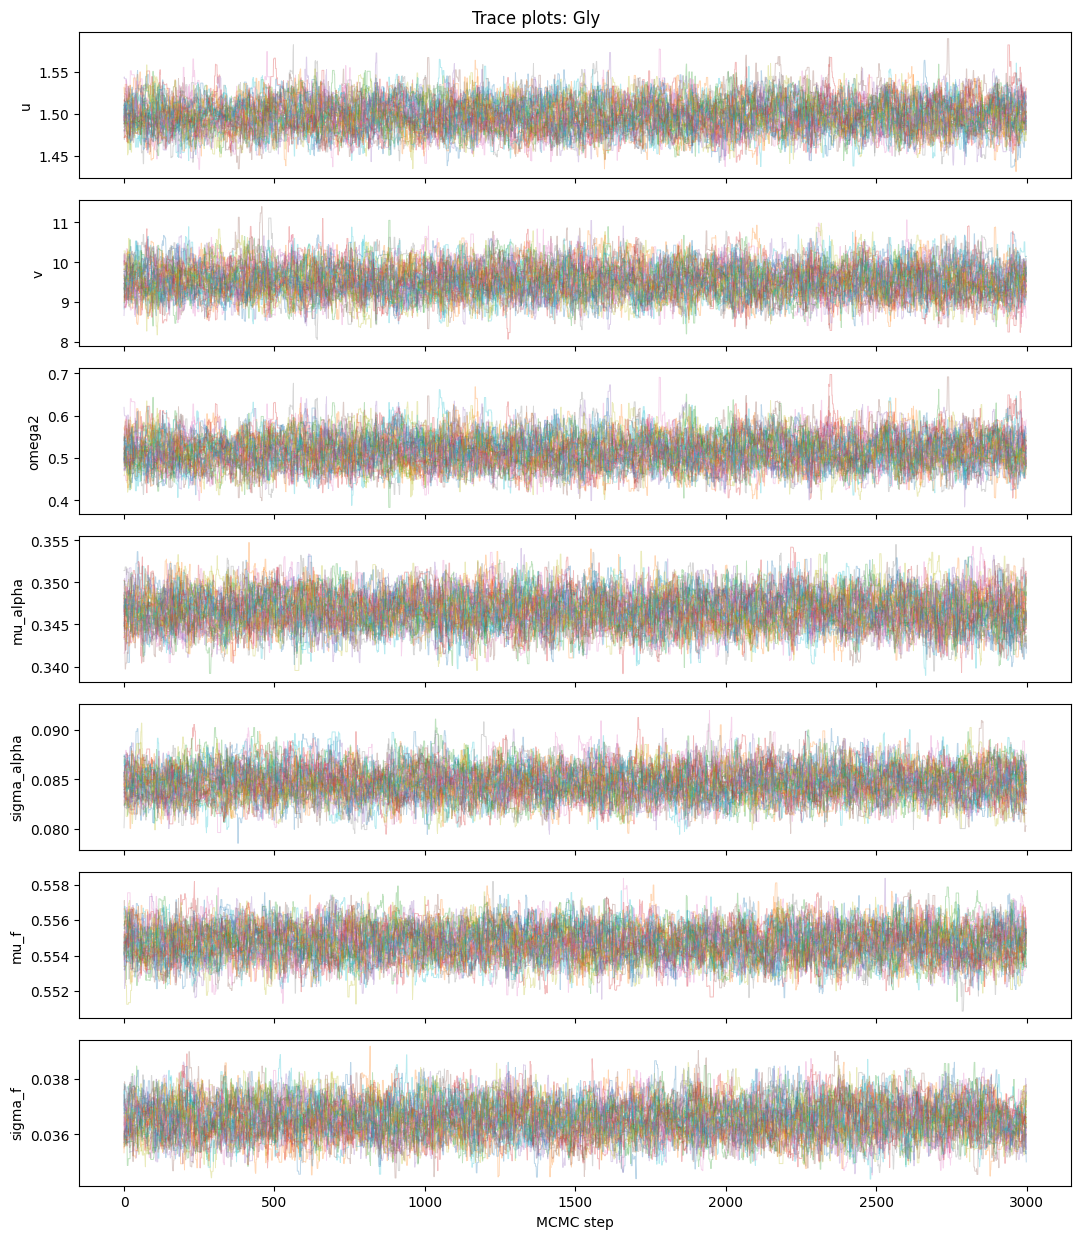

In [57]:

def plot_trace(chain, sugar):
    """Plot MCMC traces for all parameters."""
    steps, walkers, n_params = chain.shape

    fig, axes = plt.subplots(n_params, 1, figsize=(11, 1.8 * n_params), sharex=True)
    if n_params == 1:
        axes = [axes]

    for j, ax in enumerate(axes):
        ax.plot(chain[:, :, j], alpha=0.3, linewidth=0.7)
        ax.set_ylabel(PARAMETER_NAMES[j])

    axes[-1].set_xlabel("MCMC step")
    fig.suptitle(f"Trace plots: {sugar}")
    fig.tight_layout()

    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"trace_plots_{sugar}.pdf", bbox_inches="tight")

    plt.show()


plot_trace(chain, SUGAR)


## 13. Corner plot

This plot is skipped automatically if the `corner` package is not installed.


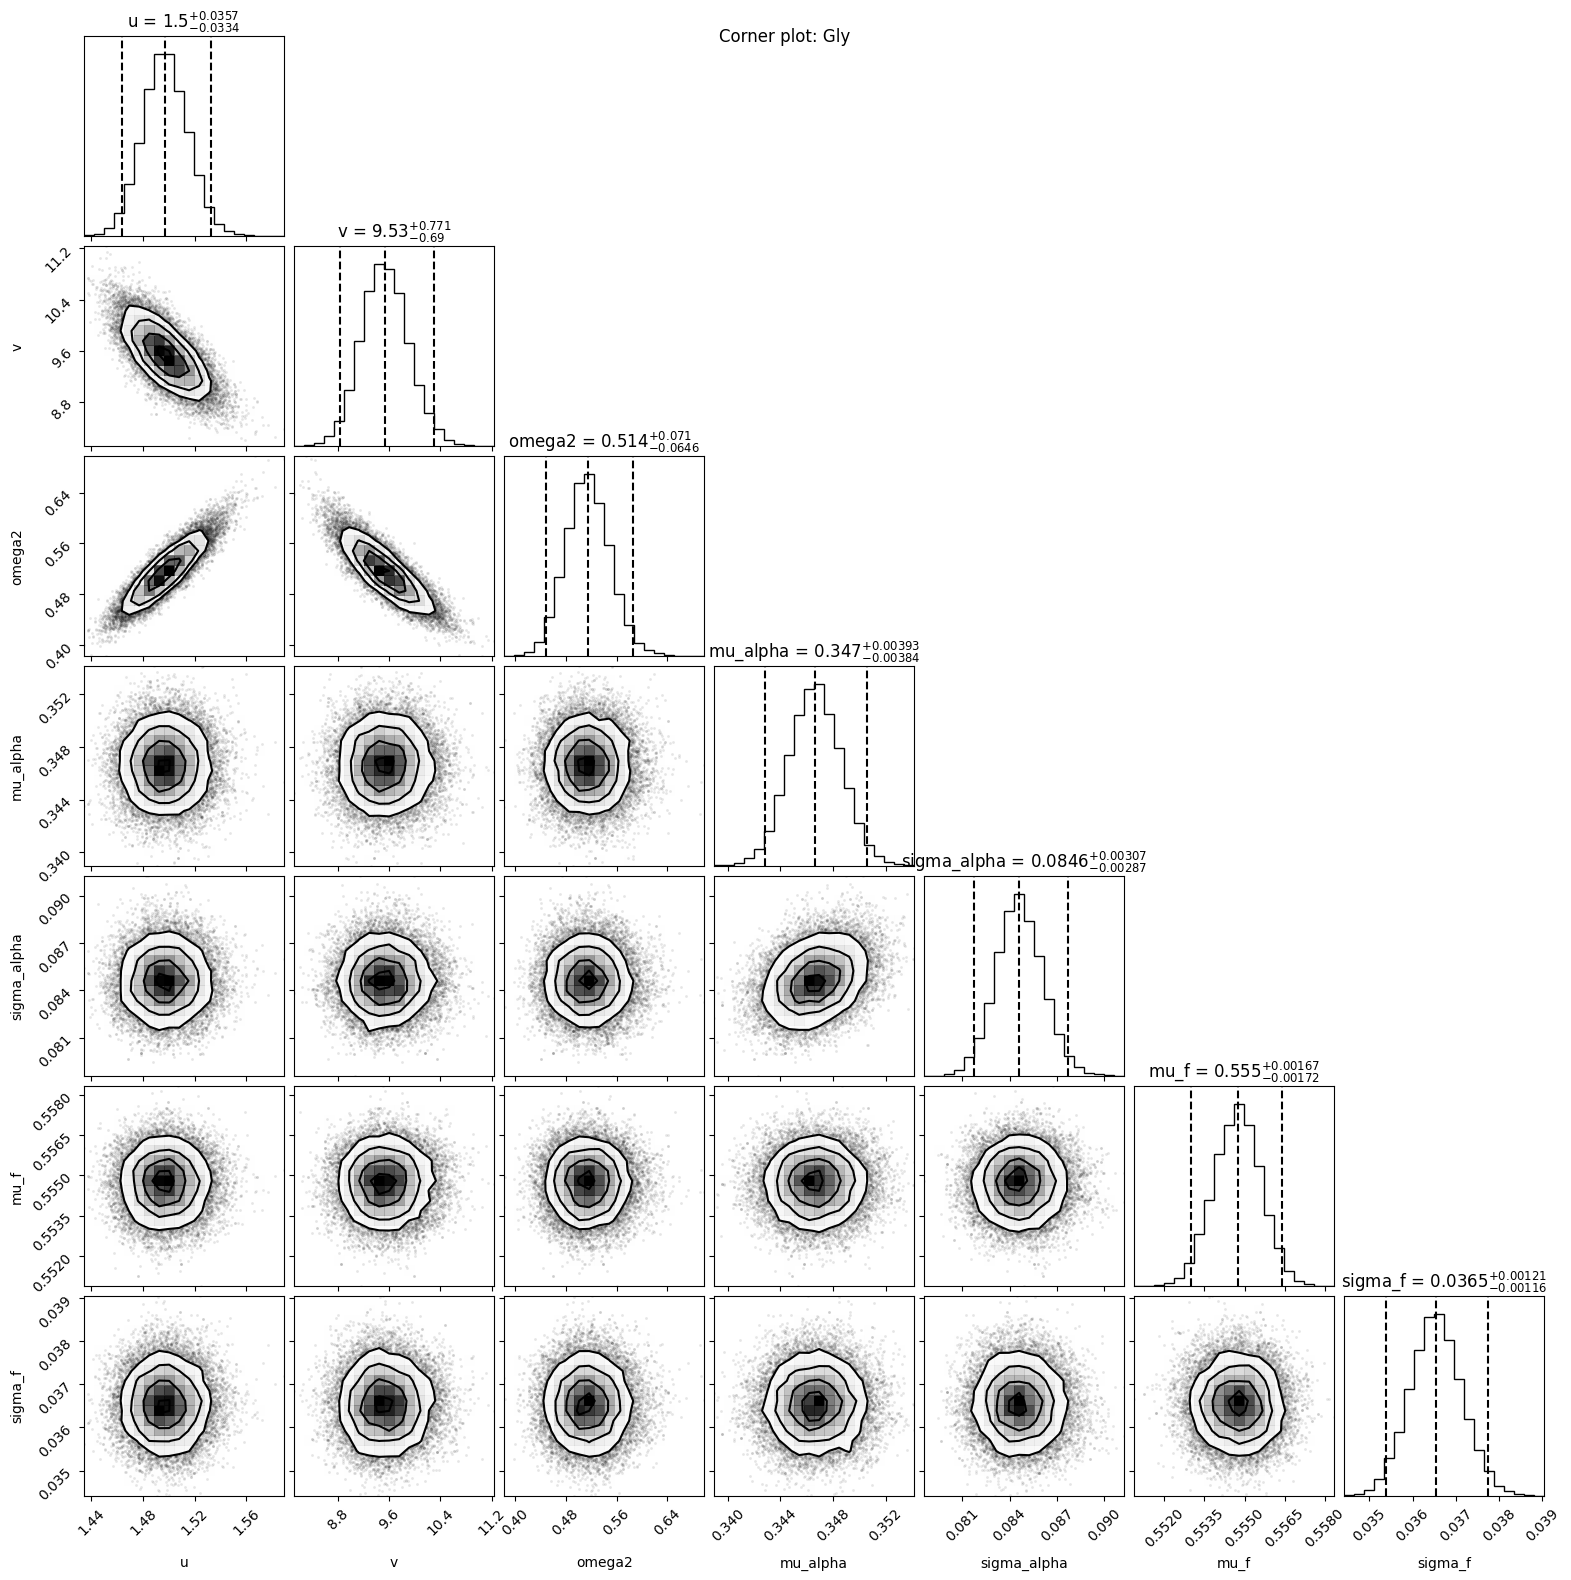

In [58]:

if HAS_CORNER:
    fig = corner.corner(
        flat_chain,
        labels=PARAMETER_NAMES,
        show_titles=True,
        title_fmt=".3g",
        quantiles=[0.025, 0.5, 0.975],
    )
    fig.suptitle(f"Corner plot: {SUGAR}")

    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"corner_plot_{SUGAR}.pdf", bbox_inches="tight")

    plt.show()
else:
    print("corner is not installed.")


## 14. Survival-fit diagnostic

The empirical survival curve uses the observed division times. The model curve is shown in two ways:

1. using median birth length and median growth rate,
2. averaging the model survival over observed birth lengths and growth rates.


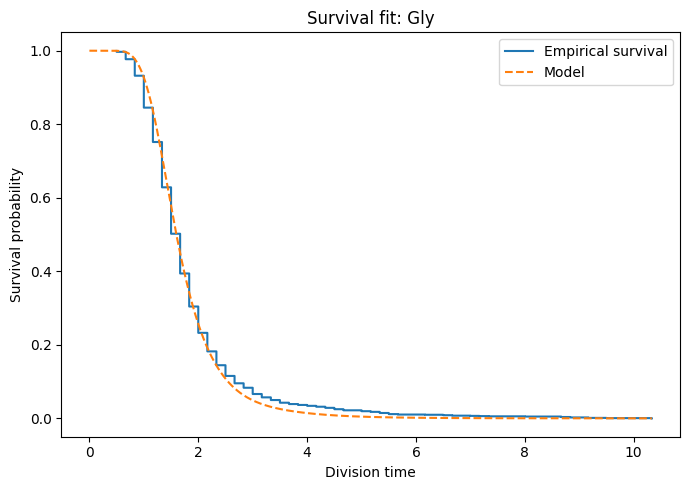

In [59]:

def empirical_survival(times):
    """Empirical survival curve from observed division times."""
    times = np.sort(np.asarray(times, dtype=float))
    times = times[np.isfinite(times)]
    survival = 1.0 - np.arange(1, len(times) + 1) / len(times)
    return times, survival


def average_model_survival(t_grid, data, params, max_observations=1000):
    """Average S(t | length_birth, alpha) over empirical observations."""
    u, v, omega2 = params[:3]

    length_birth = data["length_birth"]
    alpha = data["alpha"]

    if len(length_birth) > max_observations:
        idx = rng.choice(len(length_birth), size=max_observations, replace=False)
        length_birth = length_birth[idx]
        alpha = alpha[idx]

    curves = []
    for lb, a in zip(length_birth, alpha):
        curves.append(survival_modified(t_grid, lb, a, u, v, omega2))

    return np.nanmean(curves, axis=0)


def plot_survival_fit(data, params, sugar):
    """Compare empirical survival with fitted model survival."""
    t_emp, s_emp = empirical_survival(data["time"])

    t_grid = np.linspace(0.0, max(float(np.max(data["time"])), 1e-6), 400)
    u, v, omega2 = params[:3]

    lb_med = float(np.median(data["length_birth"]))
    alpha_med = float(np.median(data["alpha"]))

    s_median = survival_modified(t_grid, lb_med, alpha_med, u, v, omega2)
    s_average = average_model_survival(t_grid, data, params)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.step(t_emp, s_emp, where="post", label="Empirical survival")
    #ax.plot(t_grid, s_median, label="Model: median birth length and alpha")
    ax.plot(t_grid, s_average, linestyle="--", label="Model")

    ax.set_xlabel("Division time")
    ax.set_ylabel("Survival probability")
    ax.set_title(f"Survival fit: {sugar}")
    ax.legend()
    fig.tight_layout()

    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"survival_fit_{sugar}.pdf", bbox_inches="tight")

    plt.show()


plot_survival_fit(data, median_params, SUGAR)


## 15. Posterior-predictive simulation

This section simulates artificial cell lineages using fitted parameters. It follows the same lineage-generation logic used in the previous Model 2 synthetic-data notebooks, but with the modified survival model instead of the original Model 2 survival.


In [60]:

def sample_division_time(length_birth, alpha, u, v, omega2, rng, t_initial_upper):
    """Sample one division time by inverse transform sampling."""
    r = float(rng.uniform())

    def froot(t):
        return 1.0 - survival_modified(t, length_birth, alpha, u, v, omega2) - r

    upper = max(float(t_initial_upper), 1e-6)

    for _ in range(20):
        if froot(upper) > 0:
            break
        upper *= 2.0
    else:
        # The event was not bracketed. Return the upper bound as a conservative fallback.
        return float(upper)

    try:
        sol = root_scalar(froot, bracket=(0.0, upper), method="brentq")
        return float(sol.root)
    except Exception:
        return float(upper)


def simulate_modified_hazard(
    params,
    empirical_data,
    sim_lineages=SIM_LINEAGES,
    sim_generations=SIM_GENERATIONS,
    seed=RANDOM_SEED + 1,
):
    """Simulate synthetic lineages from the modified-hazard fitted model."""
    local_rng = np.random.default_rng(seed)
    u, v, omega2, mu_alpha, sigma_alpha, mu_f, sigma_f = params

    shape_alpha, scale_alpha = gamma_shape_scale(mu_alpha, sigma_alpha)
    beta_a, beta_b = beta_ab(mu_f, sigma_f)

    if shape_alpha is None or beta_a is None:
        raise ValueError("Invalid Gamma or Beta parameters for simulation.")

    initial_lengths = empirical_data["initial_mass"]
    if len(initial_lengths) == 0:
        initial_lengths = empirical_data["length_birth"]

    t_upper = max(20.0, float(np.nanpercentile(empirical_data["time"], 99)) * 5.0)

    rows = []

    for lineage in range(sim_lineages):
        length_birth = float(local_rng.choice(initial_lengths))

        for generation in range(sim_generations):
            alpha = float(scipy_gamma.rvs(shape_alpha, scale=scale_alpha, random_state=local_rng))
            f = float(scipy_beta.rvs(beta_a, beta_b, random_state=local_rng))

            t_div = sample_division_time(
                length_birth=length_birth,
                alpha=alpha,
                u=u,
                v=v,
                omega2=omega2,
                rng=local_rng,
                t_initial_upper=t_upper,
            )

            length_final = length_birth * math.exp(min(alpha * t_div, MAX_EXP_ARG))

            rows.append({
                "lineage": lineage,
                "generation": generation,
                "time": t_div,
                "alpha": alpha,
                "f": f,
                "length_birth": length_birth,
                "length_final": length_final,
            })

            length_birth = max(length_final * f, EPS)

    return pd.DataFrame(rows)


sim_df = simulate_modified_hazard(
    median_params,
    data,
    sim_lineages=SIM_LINEAGES,
    sim_generations=SIM_GENERATIONS,
)

print("Simulated dataframe shape:", sim_df.shape)
sim_df.head()


Simulated dataframe shape: (3200, 7)


,lineage,generation,time,alpha,f,length_birth,length_final
0,0,0,1.465336,0.399776,0.505878,1.839297,3.304187
1,0,1,2.415078,0.278262,0.592642,1.671515,3.273158
2,0,2,2.553996,0.341984,0.578735,1.939812,4.646049
3,0,3,1.777048,0.224631,0.475143,2.688832,4.007977
4,0,4,2.679500,0.195326,0.513756,1.904363,3.214022


## 16. Posterior-predictive histograms

These plots compare real and simulated distributions for division time, growth rate, division ratio, and birth length.


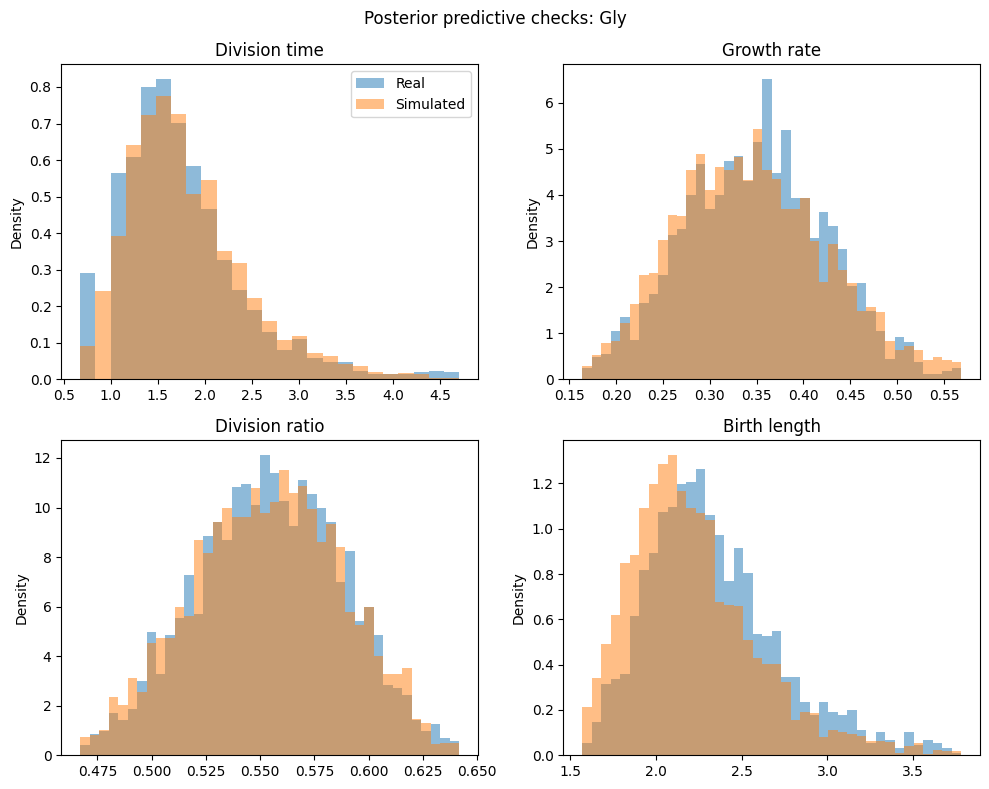

In [61]:

def plot_posterior_predictive_histograms(
    real_df,
    sim_df,
    sugar,
    division_time_bins=DIVISION_TIME_BINS,
    other_bins=OTHER_BINS,
):
    """Compare real and simulated marginal distributions."""
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()

    specs = [
        ("time", "Division time", division_time_bins),
        ("alpha", "Growth rate", other_bins),
        ("f", "Division ratio", other_bins),
        ("length_birth", "Birth length", other_bins),
    ]

    for ax, (col, title, n_bins) in zip(axes, specs):
        real_vals = real_df[col].to_numpy(float)
        sim_vals = sim_df[col].to_numpy(float)

        vals = np.concatenate([
            real_vals[np.isfinite(real_vals)],
            sim_vals[np.isfinite(sim_vals)],
        ])

        if len(vals) < 3:
            ax.set_title(f"{title}: not enough data")
            continue

        lo, hi = np.percentile(vals, [1, 99])
        bins = np.linspace(lo, hi, n_bins + 1) if hi > lo else n_bins

        ax.hist(real_vals, bins=bins, density=True, alpha=0.5, label="Real")
        ax.hist(sim_vals, bins=bins, density=True, alpha=0.5, label="Simulated")
        ax.set_title(title)
        ax.set_ylabel("Density")

    axes[0].legend()
    fig.suptitle(f"Posterior predictive checks: {sugar}")
    fig.tight_layout()

    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"posterior_predictive_{sugar}.pdf", bbox_inches="tight")

    plt.show()


plot_posterior_predictive_histograms(df_sugar, sim_df, SUGAR)


## 17. Real and simulated autocorrelation functions

The original notebook plotted simulated ACF only. This revised version also computes the ACF from real lineages, following the idea of the later Model 2 ACF notebooks.

Lag 0 is shown as 1 by definition. The more useful comparison is usually lags 1 and above.


C:\Users\Asus\AppData\Local\Temp\ipykernel_26664\3097982243.py:38: RuntimeWarning: Mean of empty slice
  return np.arange(max_lag + 1), np.nanmean(acfs, axis=0)


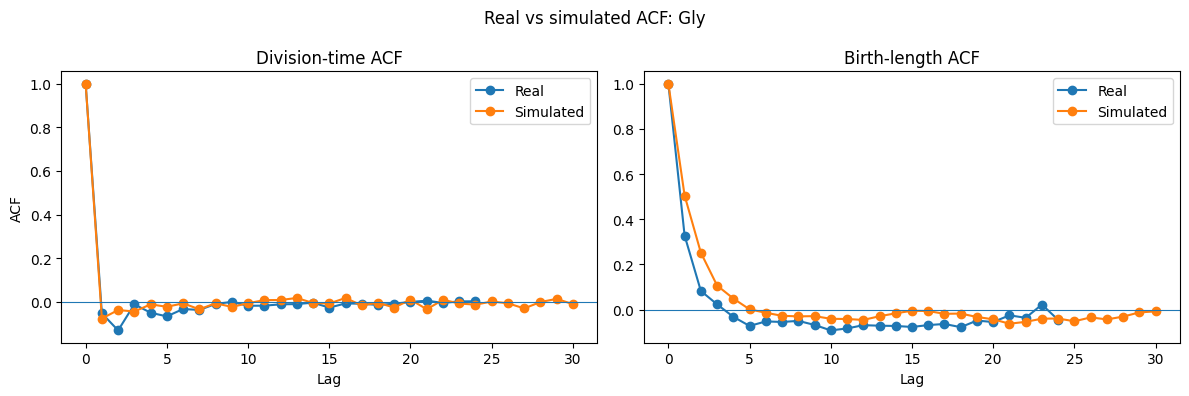

In [62]:

def acf_1d(x, max_lag=ACF_MAX_LAG):
    """Compute autocorrelation up to max_lag for one sequence."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    out = np.full(max_lag + 1, np.nan)
    if len(x) < 3:
        return out

    x_centered = x - np.mean(x)
    denom = np.sum(x_centered**2)
    if denom <= 0:
        return out

    out[0] = 1.0
    n = len(x_centered)

    for lag in range(1, max_lag + 1):
        if lag >= n:
            continue
        out[lag] = np.sum(x_centered[:-lag] * x_centered[lag:]) / denom

    return out


def mean_acf_by_lineage(df, value_col, lineage_col="lineage", generation_col="generation", max_lag=ACF_MAX_LAG):
    """Average ACF across lineages."""
    acfs = []

    for _, sub in df.groupby(lineage_col):
        sub = sub.sort_values(generation_col)
        if len(sub) >= 3:
            acfs.append(acf_1d(sub[value_col], max_lag=max_lag))

    if len(acfs) == 0:
        return np.arange(max_lag + 1), np.full(max_lag + 1, np.nan)

    return np.arange(max_lag + 1), np.nanmean(acfs, axis=0)


def plot_real_vs_simulated_acf(real_df, sim_df, sugar, max_lag=ACF_MAX_LAG):
    """Compare real and simulated ACF for division time and birth length."""
    lags, real_time_acf = mean_acf_by_lineage(real_df, "time", max_lag=max_lag)
    _, sim_time_acf = mean_acf_by_lineage(sim_df, "time", max_lag=max_lag)

    _, real_birth_acf = mean_acf_by_lineage(real_df, "length_birth", max_lag=max_lag)
    _, sim_birth_acf = mean_acf_by_lineage(sim_df, "length_birth", max_lag=max_lag)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

    axes[0].plot(lags, real_time_acf, marker="o", label="Real")
    axes[0].plot(lags, sim_time_acf, marker="o", label="Simulated")
    axes[0].axhline(0, linewidth=0.8)
    axes[0].set_title("Division-time ACF")
    axes[0].set_xlabel("Lag")
    axes[0].set_ylabel("ACF")
    axes[0].legend()

    axes[1].plot(lags, real_birth_acf, marker="o", label="Real")
    axes[1].plot(lags, sim_birth_acf, marker="o", label="Simulated")
    axes[1].axhline(0, linewidth=0.8)
    axes[1].set_title("Birth-length ACF")
    axes[1].set_xlabel("Lag")
    axes[1].legend()

    fig.suptitle(f"Real vs simulated ACF: {sugar}")
    fig.tight_layout()

    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"acf_real_vs_simulated_{sugar}.pdf", bbox_inches="tight")

    plt.show()


plot_real_vs_simulated_acf(df_sugar, sim_df, SUGAR, max_lag=ACF_MAX_LAG)


## 18. Log-likelihood diagnostic: vary `u`

This section is inspired by the previous `plots_model2` diagnostic notebooks. It checks whether the fitted value of `u` lies near a high-likelihood region while keeping all other parameters fixed.


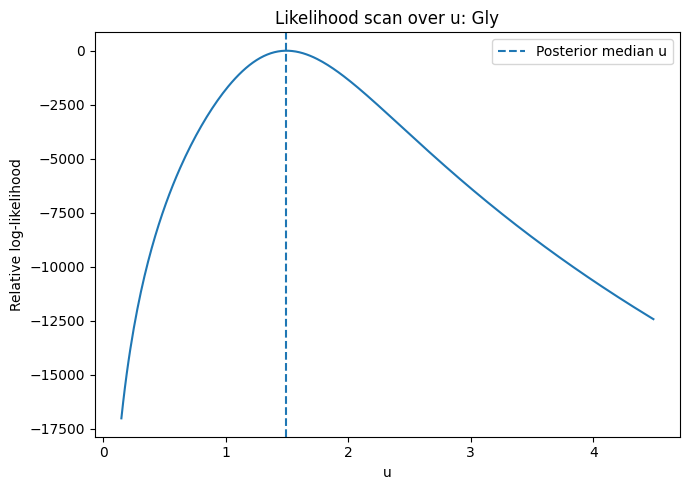

In [63]:

def plot_likelihood_scan_u(params, data, sugar, n_grid=300):
    """Scan log-likelihood while varying u and keeping other parameters fixed."""
    params = np.asarray(params, dtype=float)
    u_hat = params[0]

    lo = max(PRIOR_BOUNDS["u"][0], u_hat * 0.1)
    hi = min(PRIOR_BOUNDS["u"][1], u_hat * 3.0)

    if not (hi > lo):
        print("Could not build a valid u-scan interval.")
        return

    us = np.linspace(lo, hi, n_grid)
    lls = []

    for u_val in us:
        test_params = params.copy()
        test_params[0] = u_val
        lls.append(log_likelihood(test_params, data))

    lls = np.asarray(lls)
    lls = lls - np.nanmax(lls)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(us, lls)
    ax.axvline(u_hat, linestyle="--", label="Posterior median u")
    ax.set_xlabel("u")
    ax.set_ylabel("Relative log-likelihood")
    ax.set_title(f"Likelihood scan over u: {sugar}")
    ax.legend()
    fig.tight_layout()

    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"likelihood_scan_u_{sugar}.pdf", bbox_inches="tight")

    plt.show()


plot_likelihood_scan_u(median_params, data, SUGAR)


## 19. How to use this notebook

To analyze another sugar, change this line in the settings cell:

```python
SUGAR = "Ace"
```

For a final-quality posterior run, increase:

```python
BURN_STEPS
N_STEPS
```

Recommended checks before trusting a final run:

1. the mean acceptance fraction should not be extremely small or extremely high,
2. trace plots should not show strong drift,
3. the posterior should not be stuck on prior boundaries,
4. posterior-predictive histograms should be compared with the real distributions,
5. ACF plots should be inspected for real-vs-simulated mismatch.

The saved chain contains the sampled parameters and one extra `log_probability` column, so it can be reused by later posterior-analysis notebooks.
